# Linear Regression vs. Local LLM + RAG

Exam comparison exercise: predict the **same numerical target** with two different approaches and compare the errors.

**Task:** predict the sale price of an apartment (thousand DKK) from its size (m²).
The data is synthetic and generated with a fixed seed, so anyone can reproduce it.

**Rules from the exam, and how this notebook follows them**

| Exam rule | How it is handled here |
|---|---|
| Same inputs for both approaches, test targets hidden | Both get the same test sizes. Test prices live in `y_test` and are first read in Step 6. A guard in Step 3 checks that no test row is in the RAG collection. |
| RAG collection holds training/reference data only | One background note plus one sentence per **training** row. |
| LLM must not call the regression model or run code | The LLM only gets text. It never sees the model, and code execution is not enabled. |
| Document what was retrieved | Step 5 shows the retrieved chunks per test case and measures how close in size they were. |
| Report measured results, including failures | A failed answer is stored as `NaN` and reported. Nothing is repaired by hand. |

**Controlled comparison.** The RAG run and the no-RAG baseline use the *same* system prompt, the *same* question and the *same* output format.
The only difference is that the RAG run also receives the retrieved chunks. There is no scaling of inputs or outputs anywhere.

**Before you run it:** Ollama must be running with `ollama pull qwen3:4b` and `ollama pull nomic-embed-text` done.
Run the cells from top to bottom.

In [1]:
import json
import math
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

OLLAMA = os.environ.get("OLLAMA_HOST", "http://localhost:11434")
if not OLLAMA.startswith("http"):
    OLLAMA = "http://" + OLLAMA
CHAT_MODEL = "qwen3:4b"
EMBED_MODEL = "nomic-embed-text"

SEED = 42        # data, split and LLM sampling seed
N_ROWS = 45      # synthetic rows
N_TEST = 5       # held-out test cases
TOP_K = 5        # chunks retrieved per question
MAX_ATTEMPTS = 3 # tries per question if the reply is not a valid answer

RAG_DIR = Path("rag_data");   RAG_DIR.mkdir(exist_ok=True)
FIG_DIR = Path("figures");    FIG_DIR.mkdir(exist_ok=True)
OUT_DIR = Path("responses");  OUT_DIR.mkdir(exist_ok=True)

## Step 0: Check Ollama and start from a clean model state

Earlier runs sometimes produced off-topic replies that disappeared after `ollama stop qwen3:4b`.
To avoid stale model state, the chat model is unloaded here before the experiment starts.
The versions are recorded so the run can be documented.

In [2]:
try:
    version = requests.get(f"{OLLAMA}/api/version", timeout=10).json().get("version", "unknown")
    installed = [m["name"] for m in requests.get(f"{OLLAMA}/api/tags", timeout=10).json()["models"]]
except requests.RequestException as e:
    raise SystemExit(f"Cannot reach Ollama at {OLLAMA}. Start it first. ({e})")

for needed in (CHAT_MODEL, EMBED_MODEL):
    if not any(name == needed or name.startswith(needed + ":") for name in installed):
        raise SystemExit(f"Model {needed} is not installed. Run: ollama pull {needed}")

# keep_alive=0 unloads the model from memory (same effect as `ollama stop`)
requests.post(f"{OLLAMA}/api/generate", json={"model": CHAT_MODEL, "keep_alive": 0}, timeout=120)
print("Ollama version:", version)
print("Installed models:", installed)

Ollama version: 0.40.18
Installed models: ['nomic-embed-text:latest', 'qwen3:4b', 'qwen2.5-coder:1.5b-base', 'qwen2.5-coder:7b', 'qwen3:8b']


## Step 1: Prepare the data

- **Input:** `size_m2`, the apartment size in square metres.
- **Target:** `price_kdkk`, the sale price in thousand DKK.
- Generated as `price = 42 * size + 350 + noise`. The noise is normally distributed (mean 0, standard deviation 120)
  and stands in for everything besides size that affects a price (location, floor, condition).
- 40 rows are training/reference data and 5 are held-out test cases.

In [3]:
rng = np.random.default_rng(SEED)
size_m2 = rng.integers(30, 151, size=N_ROWS)
price = 42 * size_m2 + 350 + rng.normal(0, 120, size=N_ROWS)
df = pd.DataFrame({"size_m2": size_m2, "price_kdkk": price.round(0).astype(int)})

train_df, test_df = train_test_split(df, test_size=N_TEST, random_state=SEED)
train_df = train_df.sort_values("size_m2").reset_index(drop=True)
test_df = test_df.sort_values("size_m2").reset_index(drop=True)

# From here on the approaches only get the test INPUTS.
# The test targets stay in y_test and are first read in Step 6.
X_test = test_df[["size_m2"]]
y_test = test_df["price_kdkk"]

print(f"{len(train_df)} training rows, {len(test_df)} test cases")
print("Test inputs (m2):", X_test["size_m2"].tolist())
print("Training size range:", train_df["size_m2"].min(), "-", train_df["size_m2"].max(), "m2")

40 training rows, 5 test cases
Test inputs (m2): [37, 72, 78, 106, 107]
Training size range: 38 - 148 m2


## Step 2: Approach A, linear regression

Fit on the training rows only, then predict the held-out sizes.

In [4]:
model = LinearRegression()
model.fit(train_df[["size_m2"]], train_df["price_kdkk"])
reg_pred = model.predict(X_test)

print(f"Learned line: price = {model.coef_[0]:.2f} * size + {model.intercept_:.2f}   (true: 42 * size + 350)")
print("Regression predictions:", reg_pred.round(0).tolist())

Learned line: price = 42.70 * size + 296.52   (true: 42 * size + 350)
Regression predictions: [1876.0, 3371.0, 3627.0, 4822.0, 4865.0]


## Step 3: Approach B, build the RAG collection

The LLM may retrieve from:
- one short background note, and
- one sentence per **training** row.

Each training row is its own chunk, so a row is never split in half (character-based chunking could do that).
The collection is saved to `rag_data/rag_collection.txt` so it can be included in the submission.

In [5]:
background = (
    "Background: this dataset describes apartment sales. The sale price is given in thousand DKK "
    "and the size in square metres. In general, larger apartments sell for higher prices."
)
chunks = [background] + [
    f"An apartment of {row.size_m2} m2 sold for {row.price_kdkk} thousand DKK."
    for row in train_df.itertuples()
]
(RAG_DIR / "rag_collection.txt").write_text("\n".join(chunks), encoding="utf-8")

# Leakage guard: no test row (size + price) may appear in the collection.
for row in test_df.itertuples():
    test_sentence = f"An apartment of {row.size_m2} m2 sold for {row.price_kdkk} thousand DKK."
    assert test_sentence not in chunks, f"Test row leaked into the RAG collection: {test_sentence}"
assert len(chunks) == len(train_df) + 1

print(len(chunks), "chunks in the RAG collection. Leakage check passed.")
for c in chunks[:3]:
    print("-", c)

41 chunks in the RAG collection. Leakage check passed.
- Background: this dataset describes apartment sales. The sale price is given in thousand DKK and the size in square metres. In general, larger apartments sell for higher prices.
- An apartment of 38 m2 sold for 1891 thousand DKK.
- An apartment of 40 m2 sold for 2082 thousand DKK.


### Helper functions

- `embed` turns text into vectors (`nomic-embed-text`).
- `cosine_top_k` retrieves the most similar chunks.
- `ask_llm` sends one question and **requires a JSON answer** of the form `{"price_kdkk": 1234}`.
  Ollama enforces this format, so the reply is always parseable and there is no need to guess a number out of free text.
  A reply that is still invalid (or not a positive number) is retried up to `MAX_ATTEMPTS` times, then stored as `NaN`.
- Temperature is 0 and a fixed seed is set, to make the answers as repeatable as possible.
  Retries use a small temperature, so they do not simply repeat the same bad reply.

In [6]:
ANSWER_SCHEMA = {
    "type": "object",
    "properties": {"price_kdkk": {"type": "number"}},
    "required": ["price_kdkk"],
}


def embed(texts):
    r = requests.post(f"{OLLAMA}/api/embed", json={"model": EMBED_MODEL, "input": texts}, timeout=300)
    r.raise_for_status()
    return np.array(r.json()["embeddings"], dtype=np.float32)


def cosine_top_k(query_vec, matrix, k):
    q = query_vec / np.linalg.norm(query_vec)
    m = matrix / np.linalg.norm(matrix, axis=1, keepdims=True)
    scores = m @ q
    top = np.argsort(scores)[::-1][:k]
    return [(int(i), float(scores[i])) for i in top]


def chat_once(system, user, temperature):
    if "qwen3" in CHAT_MODEL.lower():
        user += "\n\n/no_think"          # same for RAG and no-RAG
    r = requests.post(
        f"{OLLAMA}/api/chat",
        json={
            "model": CHAT_MODEL,
            "stream": False,
            "think": False,
            "format": ANSWER_SCHEMA,
            "options": {"temperature": temperature, "seed": SEED},
            "messages": [
                {"role": "system", "content": system},
                {"role": "user", "content": user},
            ],
        },
        timeout=600,
    )
    r.raise_for_status()
    return r.json()["message"]["content"]


def read_price(text):
    """Return the price from a JSON reply, or NaN if the reply is not a valid positive number."""
    try:
        value = float(json.loads(text)["price_kdkk"])
    except (ValueError, KeyError, TypeError):
        return float("nan")
    return value if math.isfinite(value) and value > 0 else float("nan")


def ask_llm(system, user):
    """Ask up to MAX_ATTEMPTS times. Returns (price, list of raw replies)."""
    raw_replies = []
    for attempt in range(MAX_ATTEMPTS):
        raw = chat_once(system, user, temperature=0.0 if attempt == 0 else 0.1)
        raw_replies.append(raw)
        price = read_price(raw)
        if not math.isnan(price):
            return price, raw_replies
    print(f"WARNING: no valid answer after {MAX_ATTEMPTS} attempts, stored as NaN. Replies: {raw_replies}")
    return float("nan"), raw_replies


chunk_vectors = embed(chunks)
print("Embedded", chunk_vectors.shape[0], "chunks, vector size", chunk_vectors.shape[1])

Embedded 41 chunks, vector size 768


## Step 4: Let the local LLM predict the test cases (4T's prompt)

The prompt uses the 4T's:
- **Traits:** a careful data analyst.
- **Task:** predict the sale price from the size. The `{basis}` is the only part that differs between the two runs.
- **Tone:** precise, no explanations.
- **Target:** a script that parses the answer, so the reply must be JSON, and the unit is stated explicitly.

Both runs receive the identical question. Only the RAG run also receives the retrieved chunks as `Context:`.
This can take a while.

In [7]:
PROMPT_TEMPLATE = (
    "Traits: You are a careful data analyst who estimates apartment prices.\n"
    "Task: Predict the sale price of an apartment from its size, {basis}.\n"
    "Tone: Precise and matter-of-fact. No explanations.\n"
    "Target: A script that parses your answer. Reply with JSON only, in the form "
    '{"price_kdkk": <number>}, where the number is the price in thousand DKK '
    "(so 1000 means 1 million DKK)."
)
RAG_PROMPT = PROMPT_TEMPLATE.replace("{basis}", "using the example sales given in the context")
NO_RAG_PROMPT = PROMPT_TEMPLATE.replace("{basis}", "using your general knowledge of apartment prices in Denmark")


def make_question(size):
    return f"Predict the sale price (in thousand DKK) of an apartment of {int(size)} m2."


def predict_with_rag(size):
    question = make_question(size)
    hits = cosine_top_k(embed([question])[0], chunk_vectors, TOP_K)
    context = "\n".join(chunks[i] for i, _ in hits)
    price, raws = ask_llm(RAG_PROMPT, f"Context:\n{context}\n\n{question}")
    return price, raws, hits


def predict_without_rag(size):
    return ask_llm(NO_RAG_PROMPT, make_question(size))


rag_pred, no_rag_pred, retrieval_log, raw_log = [], [], [], []
for size in X_test["size_m2"]:
    p_rag, raws_rag, hits = predict_with_rag(size)
    p_plain, raws_plain = predict_without_rag(size)      # same input, no correction
    rag_pred.append(p_rag)
    no_rag_pred.append(p_plain)
    retrieval_log.append((int(size), hits))
    raw_log.append({"size_m2": int(size), "rag_replies": raws_rag, "no_rag_replies": raws_plain})
    print(f"{size} m2 -> RAG: {p_rag}   no RAG: {p_plain}")

37 m2 -> RAG: 1524.0   no RAG: 120.0
72 m2 -> RAG: 3472.0   no RAG: 1200.0
78 m2 -> RAG: 4220.0   no RAG: 1200.0
106 m2 -> RAG: 4652.0   no RAG: 1200.0
107 m2 -> RAG: 4722.0   no RAG: 1000.0


## Step 5: What was retrieved?

The exam asks you to document what the LLM retrieved. For each test case this shows the retrieved chunks and compares
them with the 5 training rows that are *actually* closest in size.
Embeddings capture what a text is about, not how close two numbers are, so retrieval may not pick the numerically closest rows.

In [8]:
train_sizes = train_df["size_m2"].to_numpy()
rows = []
for size, hits in retrieval_log:
    print(f"\n=== {size} m2")
    retrieved_sizes = []
    for rank, (i, score) in enumerate(hits, start=1):
        print(f"  {rank}. [{score:.3f}] {chunks[i]}")
        if i > 0:                                  # chunk 0 is the background note
            retrieved_sizes.append(int(train_sizes[i - 1]))
    nearest = np.sort(np.abs(train_sizes - size))[:TOP_K]
    rows.append({
        "size_m2": size,
        "retrieved_sizes": retrieved_sizes,
        "mean_size_gap_retrieved": round(float(np.mean(np.abs(np.array(retrieved_sizes) - size))), 1) if retrieved_sizes else None,
        "mean_size_gap_if_nearest": round(float(nearest.mean()), 1),
    })

print("\nSize gap (m2) between the question and the retrieved rows, vs. the 5 truly nearest rows:")
retrieval_summary = pd.DataFrame(rows)
display(retrieval_summary)


=== 37 m2
  1. [0.899] An apartment of 84 m2 sold for 3798 thousand DKK.
  2. [0.898] An apartment of 57 m2 sold for 2688 thousand DKK.
  3. [0.896] An apartment of 84 m2 sold for 3840 thousand DKK.
  4. [0.893] An apartment of 63 m2 sold for 2956 thousand DKK.
  5. [0.893] An apartment of 137 m2 sold for 6283 thousand DKK.

=== 72 m2
  1. [0.896] An apartment of 148 m2 sold for 6640 thousand DKK.
  2. [0.896] An apartment of 74 m2 sold for 3472 thousand DKK.
  3. [0.895] An apartment of 142 m2 sold for 6419 thousand DKK.
  4. [0.894] An apartment of 84 m2 sold for 3798 thousand DKK.
  5. [0.892] An apartment of 63 m2 sold for 2956 thousand DKK.

=== 78 m2
  1. [0.903] An apartment of 148 m2 sold for 6640 thousand DKK.
  2. [0.901] An apartment of 82 m2 sold for 3838 thousand DKK.
  3. [0.900] An apartment of 84 m2 sold for 3798 thousand DKK.
  4. [0.898] An apartment of 114 m2 sold for 5233 thousand DKK.
  5. [0.898] An apartment of 57 m2 sold for 2688 thousand DKK.

=== 106 m2
  1. 

,size_m2,retrieved_sizes,mean_size_gap_retrieved,mean_size_gap_if_nearest
0,37,"[84, 57, 84, 63, 137]",48.0,3.0
1,72,"[148, 74, 142, 84, 63]",33.8,8.6
2,78,"[148, 82, 84, 114, 57]",27.4,4.8
3,106,"[137, 148, 114, 130, 109]",21.6,7.6
4,107,"[137, 148, 109, 114, 131]",20.8,7.0


## Step 6: Compare the results

Only now are the real test prices used.
The error measure is the **absolute error** per case, `|prediction - actual|`, and the **mean absolute error (MAE)** over the test cases.
Units are thousand DKK.

In [9]:
results = pd.DataFrame({
    "size_m2": X_test["size_m2"].to_numpy(),
    "actual": y_test.to_numpy(),
    "regression": reg_pred.round(0),
    "llm_rag": rag_pred,
    "llm_no_rag": no_rag_pred,
})
approaches = ["regression", "llm_rag", "llm_no_rag"]
for col in approaches:
    results[f"abs_err_{col}"] = (results[col] - results["actual"]).abs().round(0)
err_cols = [f"abs_err_{c}" for c in approaches]

display(results)

summary = pd.DataFrame({
    "MAE": results[err_cols].mean().round(1).to_numpy(),
    "valid_cases": results[err_cols].notna().sum().to_numpy(),
}, index=approaches)
print("Mean absolute error (thousand DKK), over the valid answers of each approach:")
display(summary)

if (summary["valid_cases"] < len(results)).any():
    common = results.dropna(subset=approaches)
    print(f"Some answers are NaN, so these MAEs cover different cases. MAE on the {len(common)} cases where all approaches answered:")
    display(common[err_cols].mean().round(1).rename("MAE"))

results.to_csv(OUT_DIR / "results.csv", index=False)

,size_m2,actual,regression,llm_rag,llm_no_rag,abs_err_regression,abs_err_llm_rag,abs_err_llm_no_rag
0,37,1800,1876.0,1524.0,120.0,76.0,276.0,1680.0
1,72,3332,3371.0,3472.0,1200.0,39.0,140.0,2132.0
2,78,3634,3627.0,4220.0,1200.0,7.0,586.0,2434.0
3,106,4822,4822.0,4652.0,1200.0,0.0,170.0,3622.0
4,107,4925,4865.0,4722.0,1000.0,60.0,203.0,3925.0


Mean absolute error (thousand DKK), over the valid answers of each approach:


,MAE,valid_cases
regression,36.4,5
llm_rag,275.0,5
llm_no_rag,2758.6,5


In [10]:
# Markdown version of the table, ready to paste into the synopsis / experiment notes
cols = ["size_m2", "actual"] + approaches + err_cols
header = "| " + " | ".join(cols) + " |"
divider = "|" + "|".join(["---"] * len(cols)) + "|"
lines = [header, divider] + [
    "| " + " | ".join("NaN" if (isinstance(v, float) and math.isnan(v)) else f"{v:g}" for v in r) + " |"
    for r in results[cols].itertuples(index=False)
]
print("\n".join(lines))

| size_m2 | actual | regression | llm_rag | llm_no_rag | abs_err_regression | abs_err_llm_rag | abs_err_llm_no_rag |
|---|---|---|---|---|---|---|---|
| 37 | 1800 | 1876 | 1524 | 120 | 76 | 276 | 1680 |
| 72 | 3332 | 3371 | 3472 | 1200 | 39 | 140 | 2132 |
| 78 | 3634 | 3627 | 4220 | 1200 | 7 | 586 | 2434 |
| 106 | 4822 | 4822 | 4652 | 1200 | 0 | 170 | 3622 |
| 107 | 4925 | 4865 | 4722 | 1000 | 60 | 203 | 3925 |


### Figure

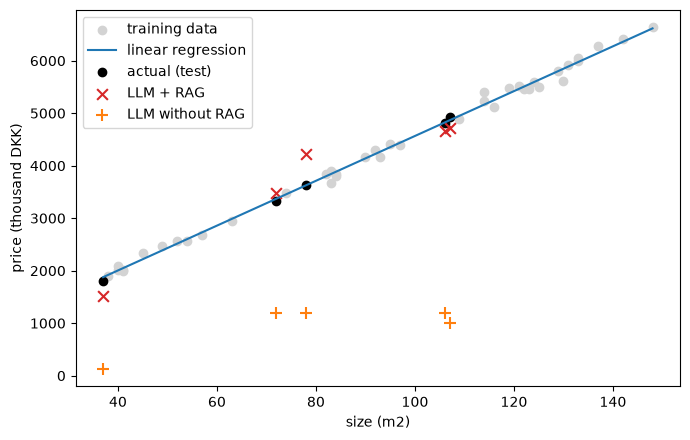

In [11]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(train_df["size_m2"], train_df["price_kdkk"], color="lightgray", label="training data")
xs = pd.DataFrame({"size_m2": np.linspace(df["size_m2"].min(), df["size_m2"].max(), 50)})
ax.plot(xs["size_m2"], model.predict(xs), label="linear regression")
ax.scatter(results["size_m2"], results["actual"], color="black", label="actual (test)")
ax.scatter(results["size_m2"], results["llm_rag"], marker="x", color="tab:red", s=60, label="LLM + RAG")
ax.scatter(results["size_m2"], results["llm_no_rag"], marker="+", color="tab:orange", s=80, label="LLM without RAG")
ax.set_xlabel("size (m2)")
ax.set_ylabel("price (thousand DKK)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "regression_vs_rag.png", dpi=200)
plt.show()

## Step 7: Save a record of the run

Raw replies, prompts and versions are saved so the numbers in the synopsis can be traced back to this exact run.
Commit the notebook **with its outputs** and the files below.

In [12]:
record = {
    "ollama_version": version,
    "chat_model": CHAT_MODEL,
    "embed_model": EMBED_MODEL,
    "seed": SEED, "top_k": TOP_K, "temperature": 0.0,
    "rag_prompt": RAG_PROMPT,
    "no_rag_prompt": NO_RAG_PROMPT,
    "raw_replies": raw_log,
}
(OUT_DIR / "run_record.json").write_text(json.dumps(record, indent=2), encoding="utf-8")
print("Saved:", OUT_DIR / "run_record.json", OUT_DIR / "results.csv", FIG_DIR / "regression_vs_rag.png", RAG_DIR / "rag_collection.txt")

Saved: responses\run_record.json responses\results.csv figures\regression_vs_rag.png rag_data\rag_collection.txt


## Step 8: Reflect (answer in the synopsis, using your own measured numbers)

1. **Which approach had the lower MAE, and by how much?** Quote the summary table.
2. **What did retrieval return?** Compare the size gap of the retrieved rows with the nearest possible rows (Step 5).
3. **Was RAG useful?** Compare `llm_rag` with `llm_no_rag`.
4. **Why do the approaches differ?** Fitted on all rows vs. at most 5 rows in a prompt; deterministic vs. text generation.
5. **When is a trained model preferable?** Exactness, speed, cost, repeatability, explainability.
6. **Limitations:** 5 test cases and one seed, synthetic linear data, a small 4B model, retrieval by embeddings, answers that can vary between runs.

### Optional experiments (change one thing at a time and write down the result)
- `TOP_K` = 1, 5 and `len(chunks)` (all rows in the prompt) to see whether retrieval is the bottleneck.
- Another `SEED`, or more test cases (`N_TEST`), and average the MAE.
- Another chat model.

Remember: the aim is to compare approaches and explain the differences, not to make the LLM win.